# The tree of a life: which curves matter?

The explorer simulates thousands of possible lives for one person. A single fan chart hides *why* lives end up far apart. This notebook asks:

1. Can we split the lives into a few **branches**, each a curve with its own uncertainty band?
2. How do we **choose** those branches without hand-picking them?
3. Does a **tree shape** appear, or just one fan?
4. Is the outcome even **one bump**? A median hides lives that split into separate groups. **Heat maps** (sections 5 and 6) show where the lives actually are, for the pipeline and for plans with a master's or a PhD.

It uses the team pipeline (`twin/`) with the learned markets switched on, the rule persona, and Alexia (P00001: 20, finishing a bachelor's in Lausanne, CHF 8,000 saved). Section 6 uses our own transition model (`twin_game_theory`), because the team pipeline has no PhD option. Running everything takes about a minute.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not ((ROOT / "twin").exists() and (ROOT / "twin_game_theory").exists()) and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
import pandas as pd

from twin import config as C
from twin.data import profiles
from twin.explore import simulate
from twin.policy.traits import from_profile
from twin.world.env import World

INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed order, never cycled
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})


HEAT = LinearSegmentedColormap.from_list("heat", [SURFACE, "#cfe0f6", "#6fa3e6", "#2a78d6", "#123f7a"])  # one hue, light to dark


def spaced(ys, gap):
    """Move label positions apart so no two are closer than `gap`, keeping their order."""
    order = np.argsort(ys)
    out = np.array(ys, float)
    for a, b in zip(order, order[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out

In [2]:
people = profiles().loc[["P00001"]]
persona = from_profile(people.iloc[0])
world = World.load()                                    # learned markets on (the default)
paths = simulate(world, people, persona, n_paths=2000, seed=C.SEED)

NW = paths.nw / 1000                                    # net worth, CHF thousands, (lives, months 0..120)
N, T = NW.shape[0], NW.shape[1] - 1
years = 2025 + np.arange(T + 1) / 12
started = (paths.action[:, :, 0] == 1) & (paths.mode[:, 1:] == C.STUDENT)   # a master's actually started
pretty = lambda t: pd.Timestamp(C.month_label(t) + "-01").strftime("%b %Y")  # noqa: E731
print(f"{N:,} lives x {T} months simulated")

2,000 lives x 120 months simulated


## 1. One fan: all lives together

This is the chart from the demo: the median life and the bands that hold half (darker) and 80% (lighter) of the lives.

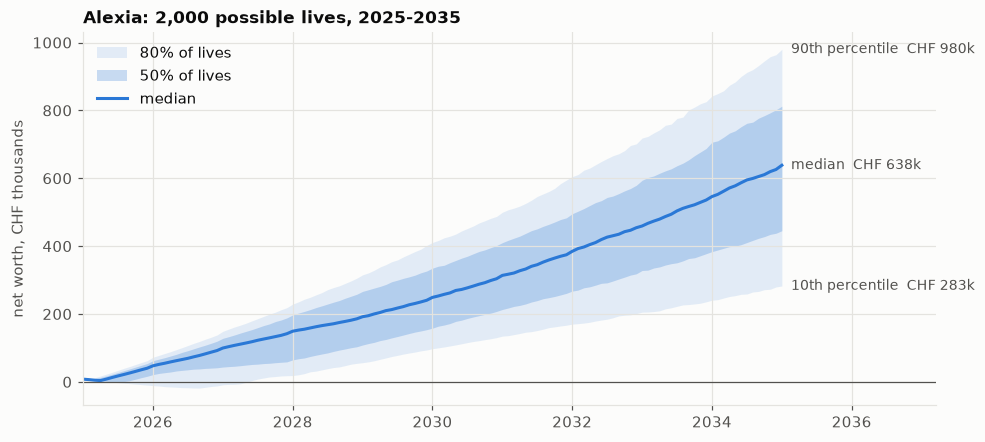

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.4))
q = np.percentile(NW, [10, 25, 50, 75, 90], axis=0)
ax.fill_between(years, q[0], q[4], color=SERIES[0], alpha=0.12, lw=0, label="80% of lives")
ax.fill_between(years, q[1], q[3], color=SERIES[0], alpha=0.25, lw=0, label="50% of lives")
ax.plot(years, q[2], color=SERIES[0], lw=2, label="median")
ax.axhline(0, color=INK2, lw=0.8)
for k, name in ((4, "90th percentile"), (2, "median"), (0, "10th percentile")):
    ax.annotate(f"{name}  CHF {q[k, -1]:,.0f}k", (years[-1], q[k, -1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
ax.set_xlim(2025, 2037.2)
ax.set_ylabel("net worth, CHF thousands")
ax.set_title("Alexia: 2,000 possible lives, 2025-2035", loc="left")
ax.legend(loc="upper left")
plt.show()

## 2. How we choose the branches

A branch is a group of lives that share a **choice or event** at some point in time. To pick them without hand-picking, we grow a small **regression tree on the lives**, forward in time:

- **Candidates:** at every January from 2025 to 2031: the work mode (full-time, part-time, studying, not working), lifestyle, a bigger flat, investing, having started a master's, and luck events (job loss, child, recession, windfall). Each is tagged as a *choice*, *luck*, or *both*: getting a full-time job needs a choice and an offer.
- **Rule:** the tree must move forward in time. Level 1 chooses among candidates in 2025-26, level 2 in 2027-28, level 3 in 2029-31. At each branch it takes the candidate that best separates **2035 net worth**, measured as the share of variance it explains.
- **Readable branches:** each side must hold at least 15% of all lives.
- **Choices only:** the tree may only split on choices (alone or with luck, like getting a full-time job). We also print the tree that luck events may split, for comparison.

Without the time rule, the tree always picks the latest snapshot (such as "part-time in 2031"), because late states are closest to the outcome. That is not a tree, just a sorting of the ending.

In [4]:
def ever(event, t):
    return paths.events[event][:, :t].any(1)


CANDIDATES = []                                   # (yes text, no text, month, kind, mask)
CANDIDATES.append(("starts a master's in Jan 2025", "no master's in Jan 2025", 0, "choice", started[:, 0]))
for t in (12, 24, 36, 48, 60, 72):
    d = pretty(t)
    CANDIDATES += [
        (f"full-time in {d}", f"not full-time in {d}", t, "both", paths.mode[:, t] == C.FULL_TIME),
        (f"part-time in {d}", f"not part-time in {d}", t, "choice", paths.mode[:, t] == C.PART_TIME),
        (f"studying in {d}", f"not studying in {d}", t, "choice", paths.mode[:, t] == C.STUDENT),
        (f"not working in {d}", f"working or studying in {d}", t, "both", paths.mode[:, t] == C.NOT_WORKING),
        (f"comfortable lifestyle in {d}", f"not comfortable in {d}", t, "choice", paths.lifestyle[:, t] == 2),
        (f"lean lifestyle in {d}", f"not lean in {d}", t, "choice", paths.lifestyle[:, t] == 0),
        (f"bigger flat by {d}", f"same flat size by {d}", t, "both", paths.tier[:, t] > paths.tier[:, 0]),
        (f"invests by {d}", f"no investments by {d}", t, "choice", paths.inv[:, t] > 1000),
        (f"started a master's by {d}", f"no master's by {d}", t, "choice", started[:, :t].any(1)),
        (f"lost a job by {d}", f"no job loss by {d}", t, "luck", ever("job_loss", t)),
        (f"a child by {d}", f"no child by {d}", t, "luck", ever("child", t)),
        (f"a recession by {d}", f"no recession by {d}", t, "luck", (paths.econ[:, :t + 1] == 2).any(1)),
        (f"a windfall by {d}", f"no windfall by {d}", t, "luck", ever("windfall", t)),
    ]
STAGES = [(0, 12), (24, 36), (48, 72)]           # months each level may choose from: 2025-26, 2027-28, 2029-31
y = NW[:, -1]
TOTAL = ((y - y.mean()) ** 2).sum()


def best_split(idx, stage, min_n, kinds):
    best = None
    sse0 = ((y[idx] - y[idx].mean()) ** 2).sum()
    for yes, no, t, kind, m in CANDIDATES:
        if not stage[0] <= t <= stage[1] or kind not in kinds:
            continue
        a, b = idx[m[idx]], idx[~m[idx]]
        if min(len(a), len(b)) < min_n:
            continue
        gain = (sse0 - ((y[a] - y[a].mean()) ** 2).sum() - ((y[b] - y[b].mean()) ** 2).sum()) / TOTAL
        if best is None or gain > best["gain"]:
            best = dict(yes=yes, no=no, t=t, kind=kind, mask=m, gain=gain)
    return best


def grow(idx, level=0, t0=0, story=(), min_share=0.15, kinds=("choice", "both")):
    node = dict(idx=idx, t0=t0, t1=T, story=story, children=[])
    split = best_split(idx, STAGES[level], int(min_share * N), kinds) if level < len(STAGES) else None
    if split:
        node.update(t1=split["t"], split=split)
        node["children"] = [grow(idx[split["mask"][idx]], level + 1, split["t"], story + (split["yes"],), min_share, kinds),
                            grow(idx[~split["mask"][idx]], level + 1, split["t"], story + (split["no"],), min_share, kinds)]
    return node


def leaves(node):
    return [node] if not node["children"] else [x for c in node["children"] for x in leaves(c)]


def show(node, pad=""):
    if node["children"]:
        s = node["split"]
        print(f"{pad}{pretty(s['t'])}: {s['yes']}?  [{s['kind']}, explains {s['gain']:.1%} of the 2035 spread]")
        for answer, child in zip(("yes", "no"), node["children"]):
            print(f"{pad}  {answer}: {len(child['idx']) / N:.0%} of lives, median 2035 CHF {np.median(y[child['idx']]):,.0f}k")
            show(child, pad + "      ")


def explained(node):
    return 1 - sum(((y[l["idx"]] - y[l["idx"]].mean()) ** 2).sum() for l in leaves(node)) / TOTAL


tree = grow(np.arange(N))
print("TREE OF CHOICES (drawn below)")
show(tree)
leaf_nodes = leaves(tree)
print(f"-> {len(leaf_nodes)} branches explain {explained(tree):.0%} of the spread of 2035 net worth; the rest is within the branches.\n")
with_luck = grow(np.arange(N), kinds=("choice", "both", "luck"))
print("FOR COMPARISON: luck events may split too")
show(with_luck)
print(f"-> {len(leaves(with_luck))} branches explain {explained(with_luck):.0%}.")

TREE OF CHOICES (drawn below)
Jan 2026: full-time in Jan 2026?  [both, explains 3.6% of the 2035 spread]
  yes: 77% of lives, median 2035 CHF 660k
      Jan 2028: full-time in Jan 2028?  [both, explains 2.5% of the 2035 spread]
        yes: 57% of lives, median 2035 CHF 677k
            Jan 2031: started a master's by Jan 2031?  [choice, explains 1.8% of the 2035 spread]
              yes: 20% of lives, median 2035 CHF 614k
              no: 37% of lives, median 2035 CHF 711k
        no: 20% of lives, median 2035 CHF 604k
  no: 23% of lives, median 2035 CHF 538k
-> 4 branches explain 8% of the spread of 2035 net worth; the rest is within the branches.

FOR COMPARISON: luck events may split too
Jan 2026: full-time in Jan 2026?  [both, explains 3.6% of the 2035 spread]
  yes: 77% of lives, median 2035 CHF 660k
      Jan 2028: full-time in Jan 2028?  [both, explains 2.5% of the 2035 spread]
        yes: 57% of lives, median 2035 CHF 677k
            Jan 2031: a recession by Jan 2031?  [lu

## 3. The tree

Each colored line is the median life of one branch. It is **thin before the branch's last split and thick after**, so you can see when the branches peel apart. A split is observed at its dot, but the gap often builds up in the years before it (studying in 2026-27 shows up as "not full-time in 2028"). Grey lines are the shared trunks, the questions are the splits, and each band holds the middle half of a branch's lives. The labels on the right give each branch's share of lives and its median at the end.

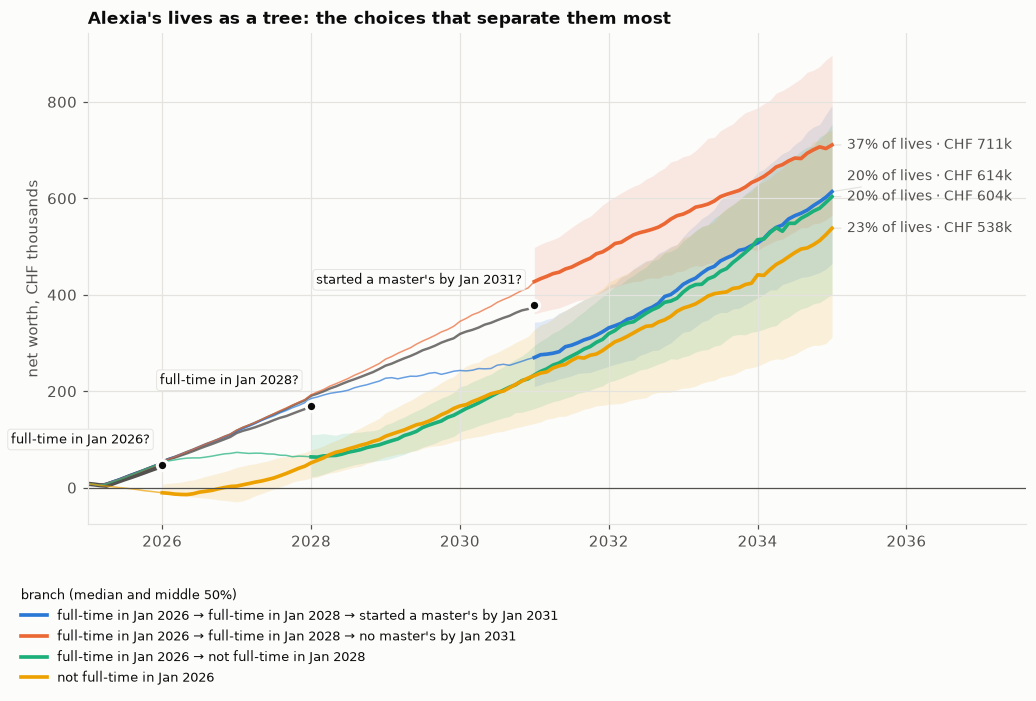

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.8))
colors = {id(l): SERIES[i] for i, l in enumerate(leaf_nodes)}
med = lambda node, t: np.median(NW[node["idx"]][:, t], axis=0)      # noqa: E731


def draw(node, depth=0):
    if node["children"]:                                           # a trunk: from 2025 to its split
        t = np.arange(0, node["t1"] + 1)
        ax.plot(years[t], med(node, t), color=INK2, lw=2.8 if depth == 0 else 1.6, alpha=1 if depth == 0 else 0.8)
        s = node["split"]
        x, m = years[s["t"]], med(node, np.array([s["t"]]))[0]
        ax.scatter([x], [m], s=46, color=INK, zorder=6, edgecolor=SURFACE, linewidth=2)
        ax.annotate(f"{s['yes']}?", (x, m), xytext=(-8, 14), textcoords="offset points", ha="right", fontsize=8.5,
                    color=INK, zorder=7, bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec=GRID, lw=0.6))
        for child in node["children"]:
            draw(child, depth + 1)
        return
    color = colors[id(node)]
    before, after = np.arange(0, node["t0"] + 1), np.arange(node["t0"], T + 1)
    lo, hi = np.percentile(NW[node["idx"]][:, after], [25, 75], axis=0)
    ax.fill_between(years[after], lo, hi, color=color, alpha=0.13, lw=0)
    ax.plot(years[before], med(node, before), color=color, lw=1.0, alpha=0.7)
    ax.plot(years[after], med(node, after), color=color, lw=2.4)


draw(tree)
ends = [np.median(NW[l["idx"], -1]) for l in leaf_nodes]
for l, ly, e in zip(leaf_nodes, spaced(ends, 42), ends):
    ax.annotate(f"{len(l['idx']) / N:.0%} of lives · CHF {e:,.0f}k", (years[-1], e), xytext=(years[-1] + 0.2, ly),
                va="center", fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=GRID, lw=0.8))
for l in leaf_nodes:
    ax.plot([], [], color=colors[id(l)], lw=2.4, label=" → ".join(l["story"]))
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlim(2025, 2037.6)
ax.set_ylabel("net worth, CHF thousands")
ax.set_title("Alexia's lives as a tree: the choices that separate them most", loc="left")
fig.legend(loc="lower left", bbox_to_anchor=(0.06, -0.16), ncol=1, fontsize=8.5, title="branch (median and middle 50%)",
           title_fontsize=8.5, alignment="left")
plt.show()

## 4. Do branches stay apart?

A choice can open a gap that **lasts** or one that **closes again**. For each split we measure, every month, the share of the spread in net worth it explains (R²): 0% means the groups are indistinguishable, and 100% means the split explains everything.

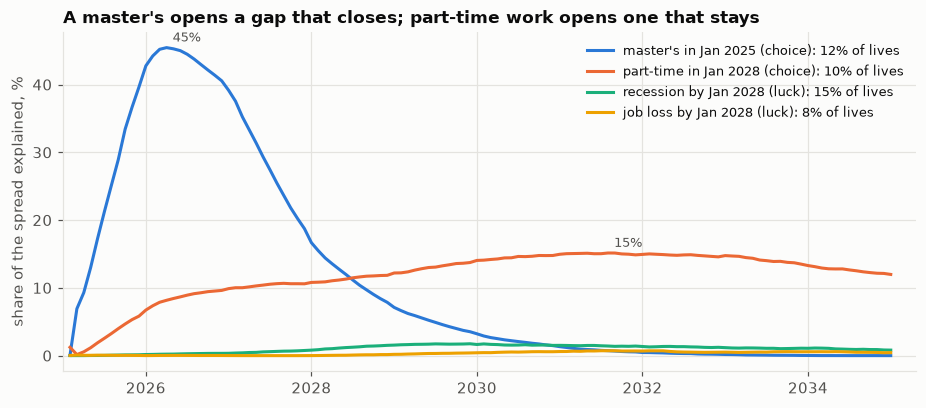

In [6]:
def r2_over_time(mask):
    out = np.full(T + 1, np.nan)
    for t in range(1, T + 1):
        x = NW[:, t]
        tot = ((x - x.mean()) ** 2).sum()
        within = sum(((x[g] - x[g].mean()) ** 2).sum() for g in (mask, ~mask) if g.any())
        out[t] = 1 - within / tot
    return out


SPLITS = [("master's in Jan 2025 (choice)", started[:, 0]),
          ("part-time in Jan 2028 (choice)", paths.mode[:, 36] == C.PART_TIME),
          ("recession by Jan 2028 (luck)", (paths.econ[:, :37] == 2).any(1)),
          ("job loss by Jan 2028 (luck)", ever("job_loss", 36))]

fig, ax = plt.subplots(figsize=(10, 4))
for (name, mask), color in zip(SPLITS, SERIES):
    r = r2_over_time(mask)
    ax.plot(years, 100 * r, color=color, lw=2, label=f"{name}: {mask.mean():.0%} of lives")
    k = int(np.nanargmax(r))
    if r[k] >= 0.05:                                     # label the peaks that matter
        ax.annotate(f"{100 * r[k]:.0f}%", (years[k], 100 * r[k]), xytext=(4, 4), textcoords="offset points",
                    fontsize=8.5, color=INK2)
ax.set_ylabel("share of the spread explained, %")
ax.set_title("A master's opens a gap that closes; part-time work opens one that stays", loc="left")
ax.legend(loc="upper right", fontsize=8.5)
ax.set_xlim(2025, 2035.3)
plt.show()

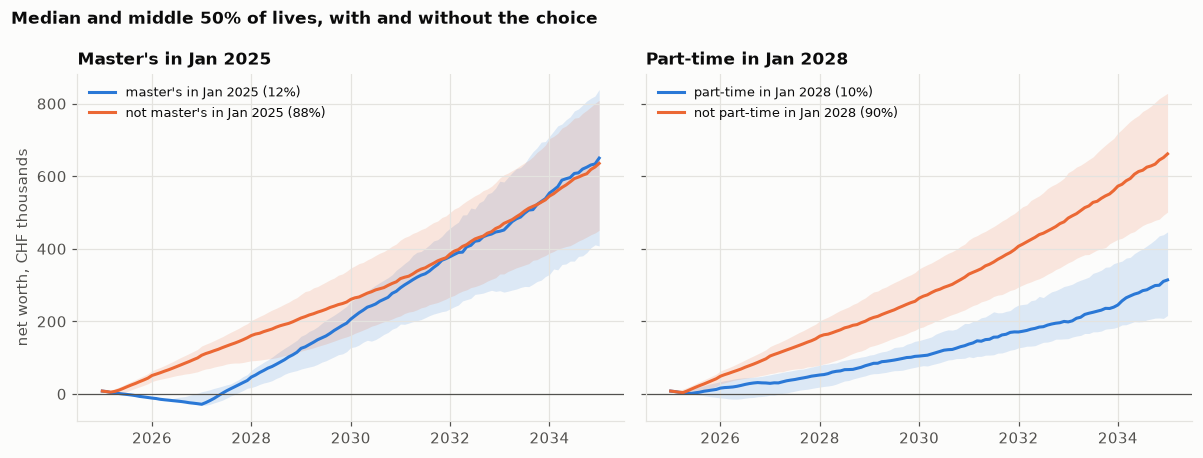

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (name, mask) in zip(axes, SPLITS[:2]):
    label = name.split(" (")[0]
    for group, color, text in ((mask, SERIES[0], label), (~mask, SERIES[1], "not " + label)):
        lo, mid, hi = np.percentile(NW[group], [25, 50, 75], axis=0)
        ax.fill_between(years, lo, hi, color=color, alpha=0.15, lw=0)
        ax.plot(years, mid, color=color, lw=2, label=f"{text} ({group.mean():.0%})")
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(label[0].upper() + label[1:], loc="left")
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("net worth, CHF thousands")
fig.suptitle("Median and middle 50% of lives, with and without the choice", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
rows = []
for name, mask in SPLITS:
    r = r2_over_time(mask)
    rows.append({"split": name, "share of lives": f"{mask.mean():.0%}",
                 "largest effect": f"{np.nanmax(r):.0%} in {pretty(int(np.nanargmax(r)))}",
                 "left in 2035": f"{r[-1]:.0%}",
                 "median 2035, yes / no": f"CHF {np.median(y[mask]):,.0f}k / {np.median(y[~mask]):,.0f}k"})
pd.DataFrame(rows).set_index("split")

,share of lives,largest effect,left in 2035,"median 2035, yes / no"
split,,,,
master's in Jan 2025 (choice),12%,45% in Apr 2026,0%,CHF 650k / 635k
part-time in Jan 2028 (choice),10%,15% in Aug 2031,12%,CHF 314k / 662k
recession by Jan 2028 (luck),15%,2% in Dec 2029,1%,CHF 572k / 651k
job loss by Jan 2028 (luck),8%,1% in Aug 2031,0%,CHF 557k / 646k


## 5. Heat map: where the lives actually are

Each column is one month. The color shows how many lives sit at each level of net worth that month, **relative to the most common level that month**: the darkest cell in each column is where most lives are. Unlike a median with a band, a heat map shows when the lives gather in **more than one place**. The panel on the right is the distribution in the last month (January 2035), and the dashed line is the median.

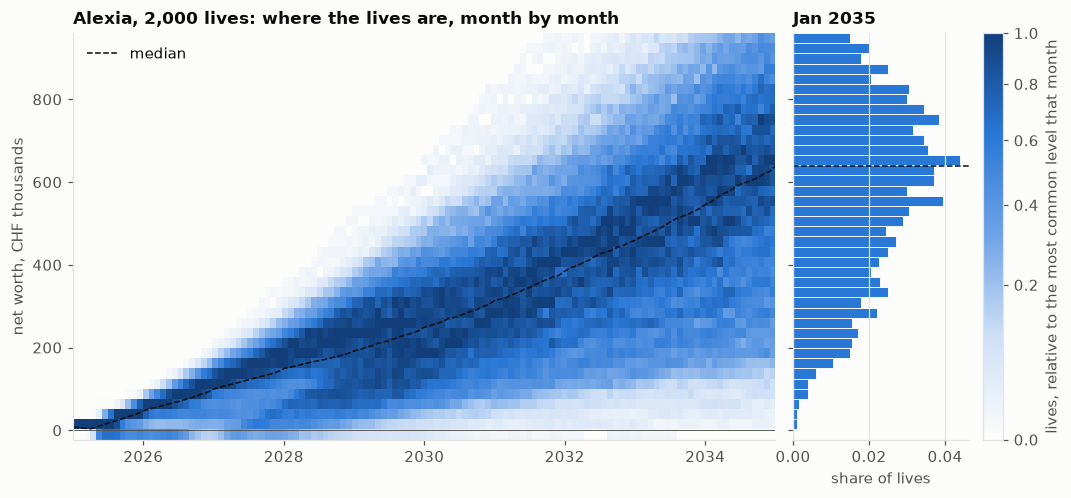

Not shown: 12.1% of lives in Jan 2035 are outside CHF -23k to 960k.


In [9]:
def shares(X, edges):
    """(bins, months): share of lives in each net-worth bin, month by month. Lives outside the range are not counted."""
    return np.stack([np.histogram(X[:, t], edges)[0] for t in range(X.shape[1])], 1) / len(X)


def heat(ax, X, edges, yrs, title=None):
    H = shares(X, edges)
    rel = H / np.maximum(H.max(0, keepdims=True), 1e-12)            # each month on its own scale
    im = ax.imshow(rel, origin="lower", aspect="auto", cmap=HEAT, norm=PowerNorm(0.6, vmin=0, vmax=1),
                   extent=[yrs[0], yrs[-1], edges[0], edges[-1]], interpolation="nearest")
    ax.plot(yrs, np.median(X, 0), color=INK, lw=1, ls="--", label="median")
    ax.axhline(0, color=INK2, lw=0.6)
    ax.grid(False)
    if title:
        ax.set_title(title, loc="left")
    return im


def final_hist(ax, x, edges, color):
    counts, _ = np.histogram(x, edges)
    ax.barh(edges[:-1], counts / len(x), height=np.diff(edges), align="edge", color=color, edgecolor=SURFACE, linewidth=0.6)
    ax.axhline(np.median(x), color=INK, lw=1, ls="--")
    ax.set_xlabel("share of lives")
    ax.grid(axis="y", visible=False)


def outside(X, edges):
    return np.mean((X < edges[0]) | (X > edges[-1]))


edges = np.linspace(np.percentile(NW, 1), np.percentile(NW, 99), 41)
fig, (ax, side) = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True, gridspec_kw={"width_ratios": [4, 1], "wspace": 0.04})
im = heat(ax, NW, edges, years, "Alexia, 2,000 lives: where the lives are, month by month")
ax.legend(loc="upper left")
ax.set_ylabel("net worth, CHF thousands")
final_hist(side, NW[:, -1], edges, SERIES[0])
side.set_title("Jan 2035", loc="left")
fig.colorbar(im, ax=[ax, side], pad=0.015, fraction=0.03, label="lives, relative to the most common level that month")
plt.show()
print(f"Not shown: {outside(NW[:, -1], edges):.1%} of lives in Jan 2035 are outside CHF {edges[0]:,.0f}k to {edges[-1]:,.0f}k.")

For the team pipeline's lives the cloud is **mostly one wide bump** that drifts up and spreads out, with a thin band of lives that stays near zero for years. Choices make branches (section 3), but each branch's fan is wide enough that they blend into one cloud. Here the median and bands are a fair summary.

## 6. Plans with a gate: master's and PhD

A plan can split lives into separate groups when it has an uncertain gate: a place you may not get, or a degree that may take much longer than planned. The team pipeline has no PhD option, so this section uses **our transition model** (`twin_game_theory/world/transition.py`) for Alexia, with three simple placeholder plans, 400 lives each:

- **Work first:** search for a job after the bachelor's and accept the first offer.
- **Master's:** apply for a master's after the bachelor's, then search for a job.
- **Master's, then PhD:** the same, then apply once for a PhD. If refused, search for a job.

All three plans use the same random numbers (common random numbers), so the differences come from the plan. This model is stricter about money than the pipeline: Alexia's student budget runs a deficit and most lives cross the spec's credit limit. That shifts every plan down, so compare the shapes, not the levels.

In [10]:
from twin_game_theory.world import spec as sp
from twin_game_theory.world.transition import Action, TransitionModel, alexia

tm = TransitionModel()


def plan_policy(plan):
    def policy(s, memory):
        allowed = tm.allowed(s)["status"]
        want = "stay"
        if s.pend == sp.P_JOB_OFFER:
            want = "accept"
        elif s.pend == sp.P_ADMIT_MASTER:
            want = "accept" if plan in ("master", "phd") else "stay"
        elif s.pend == sp.P_ADMIT_PHD:
            want = "accept" if plan == "phd" else "stay"
        elif s.W == sp.N and s.pend == sp.P_NONE:
            if plan in ("master", "phd") and s.edu == sp.BACHELOR and not memory.get("master"):
                want, memory["master"] = "apply_master", True
            elif plan == "phd" and s.edu == sp.MASTER and not memory.get("phd"):
                want, memory["phd"] = "apply_phd", True
            else:
                want = "plus"                                   # search for a job
        return Action(want if want in allowed else "stay")
    return policy


def rollout(plan, n=400, months=120):
    policy = plan_policy(plan)
    nw, edu, studied = np.zeros((n, months + 1)), np.zeros(n, int), np.zeros(n, int)
    for i in range(n):
        rng, s, memory = np.random.default_rng([7, i]), alexia(), {}
        nw[i, 0] = s.C + s.I
        for t in range(months):
            s, _ = tm.sample(s, policy(s, memory), rng, draw=i % 5)   # each life also draws one of the 5 refits
            nw[i, t + 1] = s.C + s.I
            studied[i] += s.W == sp.S
        edu[i] = s.edu
    return dict(nw=nw / 1000, edu=edu, studied=studied)


PLANS = {"work": "Work first", "master": "Master's", "phd": "Master's, then PhD"}
runs = {plan: rollout(plan) for plan in PLANS}
for plan, r in runs.items():
    print(f"{PLANS[plan]:<20} degree in 2035: " + ", ".join(f"{sp.EDU_NAMES[e]} {np.mean(r['edu'] == e):.0%}"
                                                          for e in range(4) if (r['edu'] == e).any()))

Work first           degree in 2035: bachelor 100%
Master's             degree in 2035: bachelor 1%, master 99%
Master's, then PhD   degree in 2035: bachelor 1%, master 72%, phd 27%


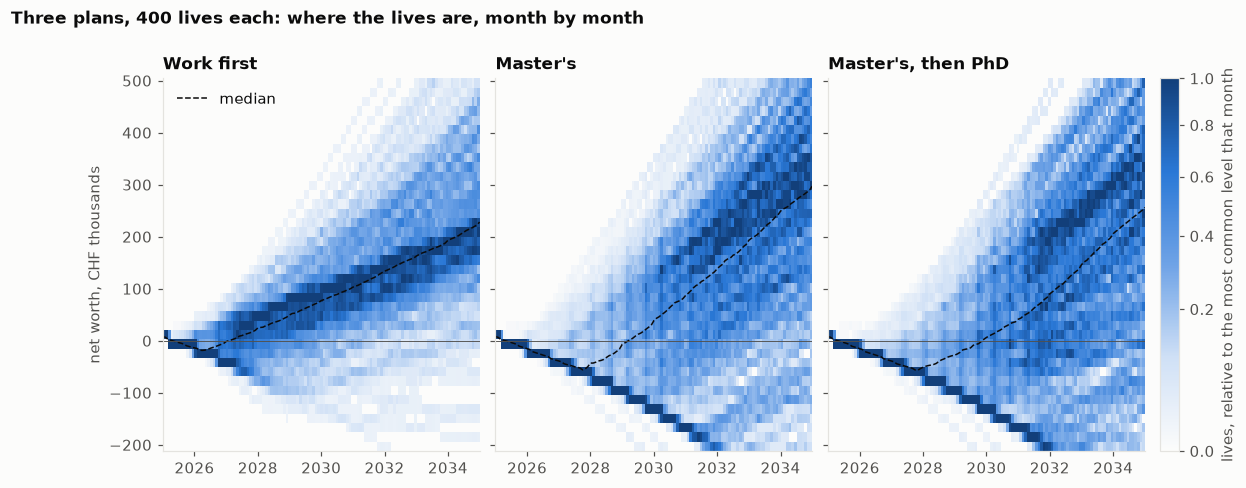

In [11]:
allnw = np.concatenate([r["nw"] for r in runs.values()])
edges2 = np.linspace(np.percentile(allnw, 1), np.percentile(allnw, 99), 41)
yrs = 2025 + np.arange(allnw.shape[1]) / 12
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), sharey=True, gridspec_kw={"wspace": 0.05})
for ax, (plan, r) in zip(axes, runs.items()):
    im = heat(ax, r["nw"], edges2, yrs, PLANS[plan])
    ax.set_xticks([2026, 2028, 2030, 2032, 2034])
axes[0].set_ylabel("net worth, CHF thousands")
axes[0].legend(loc="upper left")
fig.colorbar(im, ax=list(axes), pad=0.015, fraction=0.025, label="lives, relative to the most common level that month")
fig.suptitle("Three plans, 400 lives each: where the lives are, month by month", x=0.01, ha="left",
             fontsize=11, fontweight="bold", y=1.02)
plt.show()

**What the heat maps show.** "Work first" is mostly one band. Both master's plans have a **second, falling band**: a group whose net worth keeps dropping for the whole decade. The next chart shows who they are.

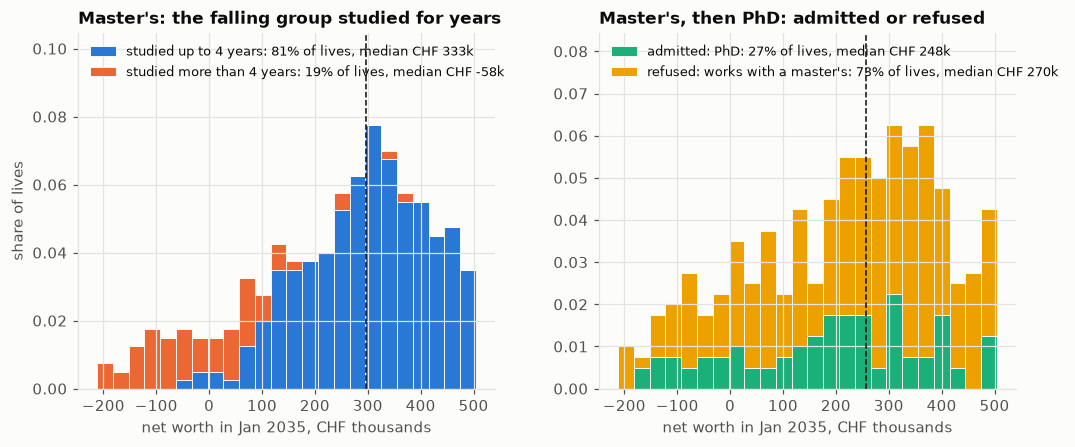

In [12]:
LONG = 48                                              # months studied in the decade
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.25})
bins = np.linspace(edges2[0], edges2[-1], 25)

ax = axes[0]
r = runs["master"]
final = r["nw"][:, -1]
bottom = np.zeros(len(bins) - 1)
for mask, label, color in ((r["studied"] <= LONG, f"studied up to {LONG // 12} years", SERIES[0]),
                           (r["studied"] > LONG, f"studied more than {LONG // 12} years", SERIES[1])):
    counts, _ = np.histogram(final[mask], bins)
    ax.bar(bins[:-1], counts / len(final), width=np.diff(bins), align="edge", bottom=bottom, color=color,
           edgecolor=SURFACE, linewidth=0.6, label=f"{label}: {mask.mean():.0%} of lives, median CHF {np.median(final[mask]):,.0f}k")
    bottom += counts / len(final)
ax.axvline(np.median(final), color=INK, lw=1, ls="--")
ax.set_xlabel("net worth in Jan 2035, CHF thousands")
ax.set_ylabel("share of lives")
ax.set_title("Master's: the falling group studied for years", loc="left")
ax.set_ylim(0, bottom.max() * 1.35)
ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
r = runs["phd"]
final = r["nw"][:, -1]
bottom = np.zeros(len(bins) - 1)
for mask, label, color in ((r["edu"] == sp.PHD, "admitted: PhD", SERIES[2]),
                           (r["edu"] != sp.PHD, "refused: works with a master's", SERIES[3])):
    counts, _ = np.histogram(final[mask], bins)
    ax.bar(bins[:-1], counts / len(final), width=np.diff(bins), align="edge", bottom=bottom, color=color,
           edgecolor=SURFACE, linewidth=0.6, label=f"{label}: {mask.mean():.0%} of lives, median CHF {np.median(final[mask]):,.0f}k")
    bottom += counts / len(final)
ax.axvline(np.median(final), color=INK, lw=1, ls="--")
ax.set_xlabel("net worth in Jan 2035, CHF thousands")
ax.set_title("Master's, then PhD: admitted or refused", loc="left")
ax.set_ylim(0, bottom.max() * 1.35)
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

In [13]:
rows = []
for plan, r in runs.items():
    f, long = r["nw"][:, -1], r["studied"] > LONG
    rows.append({"plan": PLANS[plan], "10th pct": f"{np.percentile(f, 10):,.0f}k", "median": f"{np.median(f):,.0f}k",
                 "90th pct": f"{np.percentile(f, 90):,.0f}k", "below zero in 2035": f"{(f < 0).mean():.0%}",
                 f"studied > {LONG // 12} years": f"{long.mean():.0%}",
                 "their median": f"{np.median(f[long]):,.0f}k" if long.any() else "-"})
pd.DataFrame(rows).set_index("plan")

,10th pct,median,90th pct,below zero in 2035,studied > 4 years,their median
plan,,,,,,
Work first,94k,228k,447k,3%,1%,65k
Master's,-50k,297k,530k,12%,19%,-58k
"Master's, then PhD",-91k,256k,522k,17%,36%,5k


**What this shows.**

- **The second group is lives whose studies last far too long.** Our transition model ends a study programme at random each month (a 1-in-21 chance for a master's, 1-in-48 for a PhD). That gives the right *average* length but a long tail: many lives study far longer than planned (the last two columns of the table), running a student deficit with credit at 8%. That is not realistic. The team pipeline uses a fixed 24 months (plus a 6-month delay for 10% of students) and has no such group (section 5). **Fix for our model:** count the months studied in the state and end the programme at its planned length, with a small chance of delay.
- **A PhD place, by itself, does not split the lives by 2035.** Admitted and refused end up in overlapping places: the PhD's low pay for four years is roughly offset by the higher entry level afterwards, within the ten-year window.
- **This is what the heat map is for.** The medians in sections 3 and 4 would never have shown the falling group. Here it exposed a modelling flaw; on a corrected model it would show real separate outcomes when a plan has one.

## 7. What this tells us

- **There is a tree, but a shallow one.** A few choices split the lives into branches with clearly different medians. Together they explain only part of the spread of 2035 net worth (the number printed under the tree); the rest is luck *within* each branch. So each branch is itself a fan, and the bands overlap.
- **Choices make branches; luck makes the fan.** Single luck events (a recession, a job loss) each explain 0-2% of the spread: many small shocks widen every branch rather than forming new ones.
- **Some branches merge again.** Starting a master's right away creates the largest early gap (tuition, no salary), and by the early 2030s the two groups are back together. Working part-time opens a gap that stays.
- **Look at the whole distribution, not only the median.** For the pipeline's lives the outcome is one wide bump, so the median and bands are a fair summary. When lives split into separate groups, the median can fall between them and describe nobody; the heat map and the final histogram show this, the medians do not. In our transition model it revealed a group whose studies last 5-10 years: a flaw in how the model ends a study programme, to fix.
- **How to choose the curves:** grow the tree forward in time, one life stage per level, keeping branches large enough to read. The candidates and the stages are the knobs. Change `STAGES`, `min_share` or `CANDIDATES` and re-run to try another tree.

**Caveats.** These are the rule persona's choices under the learned markets, for one person. The split statistics are associations within the simulated lives, not causal effects: people who choose part-time differ in other ways too. A causal what-if (the same lives with and without a choice) is in the explorer (`python -m twin explore --plan ...`).